<h2> Automated risk and regulatory escalation classification of banking customer complaints using text classification </h2>

Student name - Fathima Afrah Imran</br>
6COSC020W Applied AI Coursework</br>

<h3> Part A — Application area review </h3>

<h3>Literature Review</h3>

<p style="text-align:justify">
Customer complaint handling is an important operational area for banks because complaints can indicate service failures, customer harm, or potential regulatory issues. As complaints are increasingly submitted through digital channels such as online forms and email, banks are faced with large volumes of unstructured text that are difficult to triage consistently using manual processes. This has motivated the use of Artificial Intelligence (AI), particularly Natural Language Processing (NLP), to support automated routing, prioritisation and risk identification from complaint narratives (Sebastiani, 2002). A widely used real world source of consumer finance complaints is the Consumer Complaint Database published by the Consumer Financial Protection Bureau (CFPB). This dataset contains complaints about financial products and services and, where available, includes narrative text written directly by consumers (CFPB, 2025). The CFPB dataset is frequently used in applied research because it reflects realistic customer language, including informal writing styles and incomplete context, which presents challenges not found in synthetic or curated text datasets (CFPB, 2025).
    
<p style="text-align:justify">
In supervised text classification, text documents are first converted into numbers so a classifier can learn from them. A standard method is Term Frequency–Inverse Document Frequency (TF-IDF), a bag-of-words approach that gives higher weight to words that are important in the dataset (Sebastiani, 2002). Linear classifiers such as Naive Bayes and Logistic Regression are often used with TF-IDF because they are computationally efficient and relatively interpretable compared to more complex models (Sebastiani, 2002). In the context of banking complaints, studies using CFPB data have shown that classical machine learning models such as Logistic Regression can perform competitively for complaint categorisation tasks, making them suitable baselines for applied systems (Alarifi et al., 2023).
    
<p style="text-align:justify">
A key consideration in banking complaint analysis is the distinction between setiment and risk relevance. While sentiment analysis is widely used to measure customer satisfaction, sentiment alone does not reliably capture the seriousness of a complaint. A complaint describing fraud or identity theft may be written in neutral language, while an emotionally charged complaint may relate to a relatively low risk service issue. For complaint triage, classification targets that reflect issue type or risk level are therefore more appropriate than sentiment polarity alone, aligning with the broader framing of text categorisation around task-specific labels (Sebastiani, 2002). Another practical challenge is class imbalance, where high risk complaints occur much less frequently than routine complaints. In such settings, overall accuracy can be misleading, as a model may perform well on the majority class while failing to identify the minority class of interest. Research has shown that precision–recall-based evaluation is often more informative than ROC analysis for imbalanced classification problems, particularly when the cost of false negatives is high (Saito and Rehmsmeier, 2015). This has direct implications for banking applications, where failing to identify a high risk complaint can have serious consequences.

<p style="text-align:justify">
Although deep learning methods have achieved strong performance in many NLP tasks, their use in regulated domains introduces trade-offs related to interpretability, computational cost, and evaluation complexity. For applied complaint triage, simpler models can be justified when they are carefully evaluated and their limitations are clearly acknowledged (Sebastiani, 2002; Saito and Rehmsmeier, 2015). This project therefore focuses on risk oriented text classification using real banking complaint data (CFPB, 2025), with an emphasis on appropriate evaluation under class imbalance and transparent modelling choices.Part B compares several AI techniques suitable for banking complaint text classification and justifies the selection of technique for the prototype implementation.

<h3>Part B — Compare and evaluate AI techniques</h3>
<p style="text-align:justify">
This section compares three AI techniques that can be applied to the task of banking complaint text classification. Each technique is evaluated in terms of data requirements, suitability for the problem, strengths and limitations, and practical considerations.

<h4>Naive Bayes</h4>
<p style="text-align:justify">
Naive Bayes is a probabilistic classification technique based on Bayes’ theorem, with the simplifying assumption that features are conditionally independent given the class label. In text classification, this assumption is rarely true in a strict sense, but the model often performs well in practice due to the high dimensionality and sparsity of text data (Sebastiani, 2002). When applied to complaint narratives, Naive Bayes typically uses TF-IDF features as input and outputs the probability of a complaint belonging to each predefined class.
<p style="text-align:justify">
One of the main strengths of Naive Bayes is its computational efficiency. It is fast to train, requires relatively little memory, and performs well even with limited training data. These properties make it attractive for large scale complaint datasets such as the CFPB Consumer Complaint Database, where thousands of narratives may need to be processed quickly (CFPB, 2025). In addition, the probabilistic output can be useful for ranking complaints by predicted risk. However, the strong independence assumption limits the model’s ability to capture relationships between words and phrases that may signal risk or escalation. As a result, Naive Bayes may struggle with more nuanced complaint descriptions, particularly when distinguishing between medium to high risk cases. While it serves as a strong baseline, its performance may be lower than more flexible discriminative models when feature dependencies are important.

<h4>Logistic Regression</h4>
<p style="text-align:justify">
Logistic Regression is a discriminative supervised learning technique that models the probability of class membership as a function of weighted input features. In text classification tasks, it is commonly applied using TF-IDF representations of documents and has been widely adopted as a baseline in applied NLP research (Sebastiani, 2002). For banking complaint triage, Logistic Regression takes complaint narratives as input and outputs the predicted probability of each risk class.
<p style="text-align:justify">
A key advantage of Logistic Regression is its balance between performance and interpretability. Feature weights can be inspected to understand which terms contribute most strongly to specific predictions, which is particularly important in regulated domains such as banking. Studies using CFPB complaint data have shown that Logistic Regression can perform competitively for complaint categorisation tasks while remaining computationally efficient (Alarifi et al., 2023).
<p style="text-align:justify">
Logistic Regression also handles class imbalance more flexibly than Naive Bayes through techniques such as class weighting and threshold adjustment. This is important in the present application, where high risk complaints are expected to be less frequent than routine complaints. However, the model remains limited to linear decision boundaries and may not fully capture complex semantic relationships in text. Despite this limitation, its transparency and robustness make it a strong candidate for applied complaint risk classification.

<h4>Neural Network (Multilayer Perceptron)</h4>
<p style="text-align:justify">
A Multilayer Perceptron (MLP) is a feedforward neural network consisting of one or more hidden layers between the input and output layers. When applied to text classification, an MLP typically takes vectorised text features (such as TF-IDF vectors) as input and learns non-linear transformations to improve classification performance. The primary strength of an MLP is its ability to model non-linear relationships between features, which can improve performance on more complex classification tasks. In complaint analysis, this may help capture interactions between terms that jointly indicate higher risk or potential escalation. However, neural networks require more careful tuning, longer training times, and greater computational resources than simpler models.
<p style="text-align:justify">
In regulated domains such as banking, neural networks also raise concerns around interpretability and transparency. The internal representations learned by an MLP are harder to explain than the feature weights of a linear model, which may limit their suitability for complaint triage systems that require accountability. For this reason, while an MLP is a relevant comparison technique, it may not be the most appropriate choice for an initial applied prototype.

<p style="text-align:justify">
Based on the comparison above, Logistic Regression was selected for the prototype implementation in part C. This choice is justified by its strong performance in text classification tasks, ability to handle class imbalance, computational efficiency, and relative interpretability, making it well suited to applied banking complaint risk classification.

<h3>Part C(a) — System architecture</h3>

<p style="text-align:justify">
The prototype system follows a standard supervised text classification pipeline. Raw customer complaint narratives are used as input and processed through a sequence of stages to produce a predicted risk label. First, complaint text is loaded from the filtered CFPB Consumer Complaint Dataset. Basic data cleaning is applied to remove records with missing narrative text. The cleaned text is then transformed into numerical features TF-IDF, which represents the importance of words and word pairs within the collection.
<p style="text-align:justify">
The resulting TF-IDF feature vectors are provided as input to a Logistic Regression classifier trained to predict complaint risk level (high or low). The classifier outputs a predicted risk label for each complaint, which can be used to support complaint triage and prioritisation. Evaluation metrics and visualisations, including a confusion matrix and classification report, are generated to assess the effectiveness of the system.
<p style="text-align:justify">
This modular architecture allows each stage (data preparation, feature extraction, classification, and evaluation) to be inspected independently, supporting transparency and interpretability, which are important considerations in financial complaint handling.

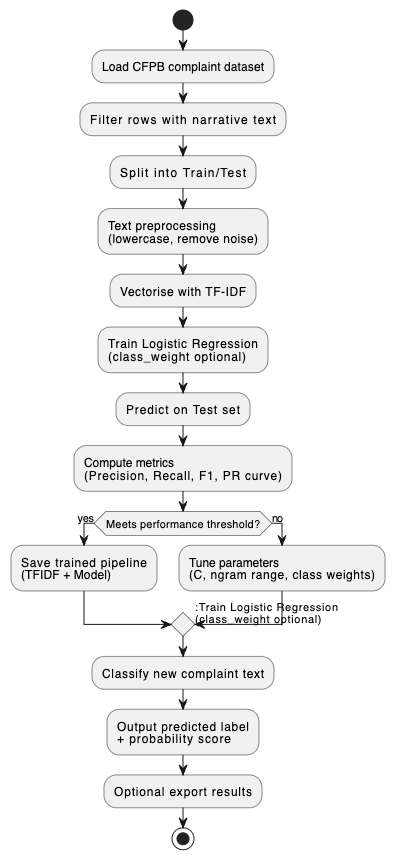

<h3>Part C(b) — Input data and preprocessing</h3>
<p style="text-align:justify">
The input to the prototype system consists of customer complaint narratives sourced from the CFPB Consumer Complaint Database. Only complaints where consumers provided consent for their narrative to be published were included. The dataset was further filtered to a one-year time window and a selected set of complaint issues relevant to financial risk and escalation, resulting in 14,597 complaint records.
<p style="text-align:justify">
Each data record includes a free text complaint narrative and an associated issue category assigned during complaint submission. These issue categories are used to define a proxy risk label. Complaints associated with issues such as incorrect information on credit reports, identity theft protection services, and fraud alerts were labelled as high risk, while more routine issues such as billing disputes or difficulty paying bills were labelled as low risk. This proxy labelling approach is justified as a practical approximation in the absence of expert annotated risk labels.
<p style="text-align:justify">
Preprocessing steps were intentionally kept minimal to preserve the original structure and meaning of customers' written text. Records with missing complaint narratives were removed. Text was converted into numerical features using TF-IDF vectorisation with English stop-word removal and a minimum document frequency threshold. This representation reduces noise from very rare terms while retaining important discriminative words and phrases. No aggressive text cleaning or lemmatisation was applied to avoid overfitting and to reflect realistic deployment conditions.

In [ ]:
#to handle and process numbers and tabular data
import pandas as pd 
import numpy as np

from pathlib import Path #to handle file path so notebook remains self contained

#ML libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.pyplot as plt #to create plots and visualisations 

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/afrahimran/AppliedAICW/main/complaints_filtered.csv"
data_path = Path("complaints_filtered.csv")

try:
    if data_path.exists() and data_path.stat().st_size > 0:
        df = pd.read_csv(data_path) #load the dataset into a pandas DataFrame
    else:
        df = pd.read_csv(DATA_URL)
        df.to_csv(data_path, index=False)
except Exception as e:
    raise RuntimeError(
        f"Failed to load dataset from {DATA_URL} and local cache {data_path}. "
        f"Error: {e}"
    )

df = df[["Consumer complaint narrative", "Issue"]].dropna() #select columns needed, rows with missing values are removed 
df.shape #confirm no. of rows and columns

In [ ]:
#define complaint issues that are considered higher risk
high_risk_issues = [
    "Incorrect information on your report",
    "Credit monitoring or identity theft protection services",
    "Problem with fraud alerts or security freezes"
]

#high risk issues are labelled as 'high', all others as 'low'
def map_risk(issue):
    return "high" if issue in high_risk_issues else "low"

df["risk_label"] = df["Issue"].apply(map_risk) #apply the risk mapping to create target variable
df["risk_label"].value_counts() #display the distribution of risk labels to inspect class balance

In [ ]:
#visualise the distribution of high and low risk complaint labels
df["risk_label"].value_counts().plot(kind="bar", color="pink")
plt.title("Risk Label Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Complaints")
plt.show()

In [ ]:
#separate input text and target labels
X = df["Consumer complaint narrative"]
y = df["risk_label"]

#split data into training and testing 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
#convert text data into TF-IDF feature vectors
vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=5
)

#fit on training data and transform both sets
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [ ]:
#train logistic regression model with class imbalance handling
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train_vec, y_train)

In [ ]:
#predict risk labels on the test set and display evaluation metrics
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred))

In [ ]:
#generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["low", "high"])

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [ ]:
#predict risk level for a new complaint text
def predict_risk(text):
    text_vec = vectorizer.transform([text])
    return model.predict(text_vec)[0]

#simple demo
user_text = input("Enter a complaint text to assess risk :\n")

if user_text.strip():
    prediction = predict_risk(user_text)
    print("\nPredicted risk level :", prediction)
else:
    print("No input provided.")

<h3>Part D — Testing and evaluation</h3>

<p style="text-align:justify">
The prototype was evaluated using a stratified train–test split, ensuring that the distribution of high and low risk complaints was preserved across training and testing sets. Logistic Regression was trained on TF-IDF features derived from the training data and evaluated on unseen test data. Performance was assessed using precision, recall, F1-score, overall accuracy, and a confusion matrix.
    
<p style="text-align:justify">
The model achieved an overall accuracy of approximately 91.5%. Performance on the low risk class was strong, with high precision and recall. For the high risk class, recall was higher than precision, indicating that the model successfully identified the majority of high risk complaints, although some low-risk complaints were incorrectly flagged as high risk. This behaviour is appropriate for a risk triage context, where failing to identify serious complaints may be more costly than reviewing additional low risk cases.
    
<p style="text-align:justify">
The confusion matrix shows that a small number of high risk complaints were misclassified as low risk. Manual inspection of misclassified examples revealed that some complaints describing fraud or identity issues were labelled as low risk due to the proxy labelling strategy based on issue categories rather than narrative content. This demonstrates a key limitation of using administrative labels as ground truth. Overall, the results indicate that the prototype is effective as a first pass complaint triage tool. However, its performance is constrained by label quality and class imbalance. Improvements could include expert labelled training data, more granular risk categories, or the integration of additional contextual features. These findings demonstrate both the strengths and limitations of the implemented approach.

<h3>Part E - Equity, diversity, inclusion and sustainability (EDI)</h3>

<p style="text-align:justify">
From an EDI perspective, the prototype raises several considerations. Complaint narratives are written by consumers with varying levels of literacy, language proficiency, and access to digital tools. Differences in writing style, grammar, and vocabulary may influence model predictions, potentially disadvantaging certain groups. As the model relies on textual patterns, complaints written in non-standard English or with limited detail may be less accurately classified. These risks show the importance of human oversight and careful deployment of automated triage systems.
<p style="text-align:justify">
Ethically, the system is intended as a decision-support tool rather than a fully automated decision maker. Human review remains essential, particularly for high risk classifications that may affect customer outcomes. Transparency and explainability are supported through the use of an interpretable model and clear evaluation metrics.
<p style="text-align:justify">
From an environmental sustainability perspective, the prototype uses lightweight machine learning techniques with modest computational requirements. TF-IDF vectorisation and Logistic Regression are significantly less resource-intensive than deep learning models, reducing energy consumption during training and inference. Data storage requirements are also limited, as only a filtered subset of the CFPB dataset is used. In a production setting, further efficiency could be achieved through incremental training, model reuse, and periodic retraining rather than continuous model updates.

<p style="text-align:justify">
<h3>Use of Generative AI (Disclosure)</h3>
ChatGPT was used to evaluate feasible project directions, clarify programming concepts, assist in interpreting error messages, and refine written explanations for improved academic tone and clarity. All external sources used are cited.

<h3>References</h3>
<p style="text-align:justify">
Alarifi, G., Rahman, M. F., & Hossain, M. S. (2023). Prediction and analysis of customer complaints using machine learning techniques. International Journal of E-Business Research, 19(1). https://doi.org/10.4018/IJEBR.319716 (Accessed: 26th December 2025).

<p style="text-align:justify">
Consumer Financial Protection Bureau (CFPB) (2025) Consumer Complaint Database. Available at: https://www.consumerfinance.gov/data-research/consumer-complaints/ (Accessed: 26th December 2025).

<p style="text-align:justify">
Saito, T. and Rehmsmeier, M. (2015) ‘The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets’, PLOS ONE, 10(3), e0118432. Available at: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432 (Accessed: 26th December 2025).

<p style="text-align:justify">
Sebastiani, F. (2002) ‘Machine Learning in Automated Text Categorization’, ACM Computing Surveys, 34(1), pp. 1–47. Available at: https://nmis.isti.cnr.it/sebastiani/Publications/ACMCS02.pdf (Accessed: 27th December 2025).